# 과제 3 — VAEP로 레전드 평가하기: 요한 크루이프

- 배정 레전드: **요한 크루이프** (StatsBomb 오픈 데이터 표기: `Johan Cruyff`, player_id 39713)
- 비교 대상: **2004/05~2007/08 바르셀로나의 호나우지뉴** (`Ronaldo de Assis Moreira`, nickname `Ronaldinho`)
- 파이프라인: Week 9 노트북(`1-run-spadl-vaep.ipynb`)과 동일. 득점·실점 모델은 조교 제공 pickle(`vaep_models.pkl`)을 사용하며 새로 학습하지 않습니다.
- **Week 9 노트북과 같은 작업을 하는 셀은 그 코드 블럭을 그대로 사용**했고, 해당 셀 위에 `# [Week 9 cell]` 주석을 달았습니다.

> 데이터 참고: 과제 안내문은 크루이프 경기를 11경기로 적었지만, 오픈 데이터에 실제로 크루이프가 출전한 경기는 **10경기**입니다
> (유러피언컵 결승 1971·1972·1973, 1974 월드컵 네덜란드 5경기 — 우루과이전·불가리아전은 오픈 데이터에 없음, 1974 레알 마드리드 0-5 바르셀로나, 1978 코파 델 레이 결승).

## 0. 환경 준비 (Week 9 노트북과 동일)

In [1]:
# [Week 9 cell]
!git clone https://github.com/narame7/UOS-FootballDataAnalytics-Tutorial

Cloning into 'UOS-FootballDataAnalytics-Tutorial'...


remote: Enumerating objects: 570, done.
remote: Counting objects: 100% (171/171), done.


remote: Compressing objects: 100% (120/120), done.


remote: Total 570 (delta 73), reused 133 (delta 50), pack-reused 399 (from 2)
Receiving objects: 100% (570/570), 222.82 MiB | 66.37 MiB/s, done.


Resolving deltas: 100% (196/196), done.


In [2]:
# [Week 9 cell]
%cd 'UOS-FootballDataAnalytics-Tutorial/Week 9'

/tmp/claude-0/-home-user-FootballDataAnalyticsProject/6cccb0a6-e8de-55ad-b914-368b9e033f4b/scratchpad/run/UOS-FootballDataAnalytics-Tutorial/Week 9


/tmp/claude-0/-home-user-FootballDataAnalyticsProject/6cccb0a6-e8de-55ad-b914-368b9e033f4b/scratchpad/venv/lib/python3.10/site-packages/IPython/core/magics/osm.py:417: UserWarning: This is now an optional IPython functionality, setting dhist requires you to install the `pickleshare` library.
  self.shell.db['dhist'] = compress_dhist(dhist)[-100:]


In [3]:
# [Week 9 cell]
!pip install pandera==0.13.4 scipy==1.11.4 statsbombpy torchmetrics

In [4]:
# 제공 모델 다운로드 (조교 구글 드라이브 폴더)
!pip install gdown
!gdown --folder https://drive.google.com/drive/folders/1AQqzJw365JUyr7yI0oS9m4qjob114wWj -O models

Using cookies from /root/.cache/gdown/cookies.txt
Retrieving folder contents


Processing file 17WEUce4IQum6Th8zvpzLHSWlHZvpNP7w vaep_concedes.json
Processing file 1Ji4C9u3fkFXW-ojpdYgeZFrfOSJCwtLA vaep_models.pkl
Processing file 1qeXWM-7arwp7a1fZpqcdPXpeu4GDdkbu vaep_models_meta.json
Processing file 1SiJTMa4smQZDQmmp38z_TMzqOlDo9pTj vaep_scores.json
Retrieving folder contents completed
Building directory structure
Building directory structure completed


Downloading...
From: https://drive.google.com/uc?id=17WEUce4IQum6Th8zvpzLHSWlHZvpNP7w
To: /tmp/claude-0/-home-user-FootballDataAnalyticsProject/6cccb0a6-e8de-55ad-b914-368b9e033f4b/scratchpad/run/UOS-FootballDataAnalytics-Tutorial/Week 9/models/vaep_concedes.json
100%|█████████████████████████████████████| 74.0k/74.0k [00:00<00:00, 87.9MB/s]


Downloading...
From: https://drive.google.com/uc?id=1Ji4C9u3fkFXW-ojpdYgeZFrfOSJCwtLA
To: /tmp/claude-0/-home-user-FootballDataAnalyticsProject/6cccb0a6-e8de-55ad-b914-368b9e033f4b/scratchpad/run/UOS-FootballDataAnalytics-Tutorial/Week 9/models/vaep_models.pkl
100%|████████████████████████████████████████| 170k/170k [00:00<00:00, 159MB/s]


Downloading...
From: https://drive.google.com/uc?id=1qeXWM-7arwp7a1fZpqcdPXpeu4GDdkbu
To: /tmp/claude-0/-home-user-FootballDataAnalyticsProject/6cccb0a6-e8de-55ad-b914-368b9e033f4b/scratchpad/run/UOS-FootballDataAnalytics-Tutorial/Week 9/models/vaep_models_meta.json
100%|█████████████████████████████████████| 5.56k/5.56k [00:00<00:00, 22.8MB/s]


Downloading...
From: https://drive.google.com/uc?id=1SiJTMa4smQZDQmmp38z_TMzqOlDo9pTj
To: /tmp/claude-0/-home-user-FootballDataAnalyticsProject/6cccb0a6-e8de-55ad-b914-368b9e033f4b/scratchpad/run/UOS-FootballDataAnalytics-Tutorial/Week 9/models/vaep_scores.json
100%|█████████████████████████████████████| 75.4k/75.4k [00:00<00:00, 70.6MB/s]
Download completed


In [5]:
# [Week 9 cell]
import warnings
import pandas as pd

pd.set_option('display.max_columns', None)
warnings.simplefilter(action='ignore', category=FutureWarning)
warnings.simplefilter(action='ignore', category=pd.errors.PerformanceWarning)
warnings.filterwarnings(action="ignore", message="credentials were not supplied. open data access only")

In [6]:
# [Week 9 cell]
from tqdm.notebook import tqdm
from sklearn.metrics import (
    precision_score,
    recall_score,
    brier_score_loss,
    roc_auc_score,
    log_loss,
    f1_score,
)
from sklearn.model_selection import train_test_split
import xgboost
import torch
from torchmetrics.classification import BinaryCalibrationError
import matplotlib.pyplot as plt
import seaborn as sns

In [7]:
# [Week 9 cell]
import matplotsoccer as mps  # 축구 이벤트 데이터 시각화
from socceraction.data.statsbomb import StatsBombLoader  # StatsBomb 데이터 로더
import socceraction.spadl as spadl  # SPADL 포맷 변환 및 처리
import socceraction.vaep.features as fs
import socceraction.vaep.labels as lab
import socceraction.vaep.formula as vaepformula

In [8]:
# 과제용 추가 import / 출력 폴더
import os, json, pickle
import numpy as np
warnings.filterwarnings("ignore", category=UserWarning)   # precision 0/0 경고 등
OUT = "outputs"
os.makedirs(OUT, exist_ok=True)

### Set up the StatsBombLoader

In [9]:
# [Week 9 cell]
# StatsBomb 데이터 로더 객체를 생성합니다. 무료 공개 데이터 접근을 위해 creds를 None으로 설정합니다.
SBL = StatsBombLoader(getter="remote", creds={"user": None, "passwd": None})
SBL

In [10]:
# [Week 9 cell]
# 사용 가능한 대회 목록
competitions = SBL.competitions()
competitions

,season_id,competition_id,competition_name,country_name,competition_gender,season_name
0,281,9,1. Bundesliga,Germany,male,2023/2024
1,27,9,1. Bundesliga,Germany,male,2015/2016
2,107,1267,African Cup of Nations,Africa,male,2023
3,4,16,Champions League,Europe,male,2018/2019
4,1,16,Champions League,Europe,male,2017/2018
...,...,...,...,...,...,...
75,75,35,UEFA Europa League,Europe,male,1988/1989
76,315,53,UEFA Women's Euro,Europe,female,2025
77,106,53,UEFA Women's Euro,Europe,female,2022
78,107,72,Women's World Cup,International,female,2023


### 배정 선수·비교 대상 경기 선택
Week 9의 `train_competitions` / `test_competitions` 선택 셀과 같은 방식으로 대회를 고른 뒤, 각 경기 라인업(`SBL.players`)에 해당 선수가 있는 경기만 남깁니다.

In [11]:
# 크루이프: 1970/71~1972/73 유러피언컵(결승), 1974 월드컵, 1973/74 라리가(레알 0-5 바르사), 1977/78 코파 델 레이(결승)
legend_competitions = competitions[
    ((competitions.competition_name == "Champions League") & (competitions.season_name.isin(["1970/1971", "1971/1972", "1972/1973"])))
    | ((competitions.competition_name == "FIFA World Cup") & (competitions.season_name == "1974"))
    | ((competitions.competition_name == "La Liga") & (competitions.season_name == "1973/1974"))
    | ((competitions.competition_name == "Copa del Rey") & (competitions.season_name == "1977/1978"))
]
legend_competitions

,season_id,competition_id,competition_name,country_name,competition_gender,season_name
18,277,16,Champions League,Europe,male,1972/1973
19,71,16,Champions League,Europe,male,1971/1972
20,276,16,Champions League,Europe,male,1970/1971
24,279,87,Copa del Rey,Spain,male,1977/1978
34,51,43,FIFA World Cup,International,male,1974
57,278,11,La Liga,Spain,male,1973/1974


In [12]:
# 호나우지뉴: 바르셀로나 라리가 2004/05 ~ 2007/08
compare_competitions = competitions[
    (competitions.competition_name == "La Liga")
    & (competitions.season_name.isin(["2004/2005", "2005/2006", "2006/2007", "2007/2008"]))
]
compare_competitions

,season_id,competition_id,competition_name,country_name,competition_gender,season_name
53,40,11,La Liga,Spain,male,2007/2008
54,39,11,La Liga,Spain,male,2006/2007
55,38,11,La Liga,Spain,male,2005/2006
56,37,11,La Liga,Spain,male,2004/2005


In [13]:
# [Week 9 cell] 패턴 (train_games / test_games 셀과 동일)
legend_all_games = pd.concat([
    SBL.games(row.competition_id, row.season_id)
    for row in legend_competitions.itertuples()
]).reset_index(drop=True)

compare_all_games = pd.concat([
    SBL.games(row.competition_id, row.season_id)
    for row in compare_competitions.itertuples()
]).reset_index(drop=True)

len(legend_all_games), len(compare_all_games)

(11, 77)

In [14]:
def find_player_games(games, pattern):
    """라인업(SBL.players)에서 player_name 또는 nickname이 pattern과 맞는 선수가 뛴 경기만 남긴다."""
    keep, pid = [], set()
    for game in tqdm(list(games.itertuples()), desc="Scanning lineups"):
        p = SBL.players(game.game_id)
        hit = p[p.player_name.str.contains(pattern, na=False) | p.nickname.fillna("").str.contains(pattern)]
        if len(hit):
            keep.append(game.game_id)
            pid |= set(hit.player_id)
    return games[games.game_id.isin(keep)].sort_values("game_date").reset_index(drop=True), pid

legend_games, legend_pid = find_player_games(legend_all_games, "Cruyff|Cruijff")
compare_games, compare_pid = find_player_games(compare_all_games, "Ronaldinho|Assis Moreira")
LEGEND_ID, COMPARE_ID = legend_pid.pop(), compare_pid.pop()
print("Cruyff player_id:", LEGEND_ID, "| games:", len(legend_games))
print("Ronaldinho player_id:", COMPARE_ID, "| games:", len(compare_games))
legend_games[["game_id", "competition_id", "season_id", "game_date", "home_team_id", "away_team_id", "home_score", "away_score"]]

Scanning lineups:   0%|          | 0/11 [00:00<?, ?it/s]

Scanning lineups:   0%|          | 0/77 [00:00<?, ?it/s]

Cruyff player_id: 39713 | games: 10
Ronaldinho player_id: 25879 | games: 59


,game_id,competition_id,season_id,game_date,home_team_id,away_team_id,home_score,away_score
0,3888711,16,276,1971-06-02 22:45:00,806,952,2,0
1,3750235,16,71,1972-05-31 12:00:00,806,238,2,0
2,3888706,16,277,1973-05-30 22:30:00,806,224,1,0
3,3888713,11,278,1974-02-17 21:00:00,220,217,0,5
4,3888716,43,51,1974-06-19 21:30:00,941,790,0,0
5,3888717,43,51,1974-06-26 18:30:00,941,779,4,0
6,3888718,43,51,1974-06-30 15:00:00,2721,941,0,2
7,3888719,43,51,1974-07-03 18:30:00,941,781,2,0
8,3888720,43,51,1974-07-07 18:00:00,941,770,1,2
9,3888754,87,279,1978-04-19 21:00:00,217,208,3,1


### VAEP 특징(Feature) 및 레이블(Label) 함수 정의 (Week 9와 동일)

In [15]:
# [Week 9 cell]
xfns = [
	fs.actiontype,
	fs.actiontype_onehot,
	fs.bodypart,
	fs.bodypart_onehot,
	fs.result,
	fs.result_onehot,
	fs.goalscore,
	fs.startlocation,
	fs.endlocation,
	fs.movement,
	fs.space_delta,
	fs.startpolar,
	fs.endpolar,
	fs.team,
	fs.time,
	fs.time_delta
]

def compute_features(actions, home_team_id, nb_prev_actions=3):
	gamestates = fs.gamestates(spadl.add_names(actions), nb_prev_actions)
	gamestates = fs.play_left_to_right(gamestates, home_team_id)

	df_features = pd.concat([fn(gamestates) for fn in xfns], axis=1)
	return df_features

In [16]:
# [Week 9 cell]
yfns = [
	lab.scores,
	lab.concedes
]

def compute_labels(actions):
	df_labels = pd.concat([fn(spadl.add_names(actions)) for fn in yfns], axis=1)
	return df_labels

In [17]:
# [Week 9 cell]
def get_dataset(games):
	X_list, Y_list = [], []

	for game in tqdm(list(games.itertuples()), desc="Games processed"):
		# load data
		events = SBL.events(game.game_id)

		# StatsBomb 이벤트 데이터를 SPADL 액션 데이터로 변환합니다.
		actions = spadl.statsbomb.convert_to_actions(
				events,
				home_team_id=game.home_team_id,
				xy_fidelity_version=1,
				shot_fidelity_version=1
		)

		X_list.append(compute_features(actions, home_team_id=game.home_team_id))
		Y_list.append(compute_labels(actions))

	X = pd.concat(X_list, axis=0).reset_index(drop=True)
	Y = pd.concat(Y_list, axis=0).reset_index(drop=True)

	return X, Y

In [18]:
X_legend, Y_legend = get_dataset(legend_games)
X_compare, Y_compare = get_dataset(compare_games)
X_legend.shape, Y_legend.shape, X_compare.shape, Y_compare.shape

Games processed:   0%|          | 0/10 [00:00<?, ?it/s]

Games processed:   0%|          | 0/59 [00:00<?, ?it/s]

((18465, 163), (18465, 2), (120826, 163), (120826, 2))

### 제공 모델 불러오기
조교가 Week 9와 같은 조건으로 학습한 득점(`scores`)·실점(`concedes`) XGBoost 모델입니다. 다시 학습하지 않습니다.

In [19]:
with open("models/vaep_models.pkl", "rb") as f:
    bundle = pickle.load(f)
models = bundle["models"]
meta = bundle["meta"]

feature_names = models["scores"].get_booster().feature_names
assert list(X_legend.columns) == feature_names and list(X_compare.columns) == feature_names
print("train:", meta["train_competitions"], "| test:", meta["test"])
print("WC2018 test metrics (meta):", json.dumps(meta["metrics"], indent=1))

train: [['1. Bundesliga', '2023/2024'], ['La Liga', '2020/2021'], ['Ligue 1', '2022/2023'], ['Ligue 1', '2021/2022']] | test: FIFA World Cup 2018 (64 games)
WC2018 test metrics (meta): {
 "scores": {
  "test_auc": 0.812211918727122,
  "test_brier": 0.008876579887134242,
  "test_logloss": 0.046300905743052734,
  "test_base_rate": 0.010483795647707107,
  "train_base_rate": 0.011835044655290863
 },
 "concedes": {
  "test_auc": 0.7132605039254467,
  "test_brier": 0.002672464389637732,
  "test_logloss": 0.017971372868075385,
  "test_base_rate": 0.002716291522679867,
  "train_base_rate": 0.001912471916371131
 }
}


### 예측 및 평가 (Week 9 `evaluate` 셀 그대로 사용)
문제 2-3의 AUC·Brier score도 이 셀의 출력입니다.

In [20]:
# [Week 9 cell]
def evaluate(y, y_hat):
	bce_l1 = BinaryCalibrationError(n_bins=10, norm="l1")

	return {
		"precision": precision_score(y, y_hat > 0.5),
		"recall": recall_score(y, y_hat > 0.5),
		"f1": f1_score(y, y_hat > 0.5),
		"log_loss": log_loss(y, y_hat),
		"brier_score": brier_score_loss(y, y_hat),
		"auc": roc_auc_score(y, y_hat),
		"ece": bce_l1(torch.Tensor(y_hat.to_numpy()), torch.Tensor(y.to_numpy())).item(),
	}

In [21]:
# [Week 9 cell] 의 예측·평가 루프를 두 데이터셋에 각각 적용
metric_rows = []
Y_hats = {}
for name, X_test, Y_test in [("Cruyff", X_legend, Y_legend), ("Ronaldinho", X_compare, Y_compare)]:
	Y_hat = pd.DataFrame()
	for col in ["scores", "concedes"]:
		Y_hat[col] = [p[1] for p in models[col].predict_proba(X_test)]
		print(f"\n### {name} | {col} ###")
		metrics = evaluate(Y_test[col], Y_hat[col])

		for metric , value in metrics.items():
			print(f"{metric}: {value:.4f}")
		metric_rows.append({"dataset": name, "label": col, **metrics,
		                    "base_rate": Y_test[col].mean(), "mean_pred": Y_hat[col].mean(), "n_pos": int(Y_test[col].sum())})
	Y_hats[name] = Y_hat


### Cruyff | scores ###
precision: 0.9615
recall: 0.1190
f1: 0.2119
log_loss: 0.0529
brier_score: 0.0098
auc: 0.7635
ece: 0.0009

### Cruyff | concedes ###
precision: 0.0000
recall: 0.0000
f1: 0.0000
log_loss: 0.0152
brier_score: 0.0023
auc: 0.7010
ece: 0.0009



### Ronaldinho | scores ###
precision: 0.9645
recall: 0.1139
f1: 0.2037
log_loss: 0.0530
brier_score: 0.0101
auc: 0.7815
ece: 0.0011



### Ronaldinho | concedes ###
precision: 0.0000
recall: 0.0000
f1: 0.0000
log_loss: 0.0136
brier_score: 0.0021
auc: 0.7863
ece: 0.0004


### VAEP 값 계산 (Week 9 셀 그대로, 데이터셋마다 실행하도록 함수로만 감쌈)

In [22]:
def build_vaep_table(test_games, Y_hat):
	# ---------- [Week 9 cell] ----------
	games_verbose = tqdm(list(test_games.itertuples()), desc="Loading game data")
	df_teams, df_players, df_actions = [], [], []

	for game in games_verbose:
		# load data
		df_teams.append(SBL.teams(game.game_id))
		df_players.append(SBL.players(game.game_id))
		events = SBL.events(game.game_id)

		# StatsBomb 이벤트 데이터를 SPADL 액션 데이터로 변환합니다.
		actions = spadl.statsbomb.convert_to_actions(
				events,
				home_team_id=game.home_team_id,
				xy_fidelity_version=1,
				shot_fidelity_version=1
		)
		df_actions.append(actions)

	df_teams = pd.concat(df_teams).drop_duplicates(subset="team_id")
	df_player_games = pd.concat(df_players).reset_index(drop=True) # 경기 별 선수 정보. 경기 별 선수 정보 (position, minutes_played)은 다름)
	df_players = pd.concat(df_players).drop_duplicates(subset="player_id") # 선수 정보. 선수 정보 (name, nationality 등)은 동일)
	df_actions = pd.concat(df_actions).reset_index(drop=True)
	df_actions = pd.concat([df_actions, Y_hat], axis=1)

	# ---------- [Week 9 cell] ----------
	A = []
	for _, group_actions in tqdm(df_actions.groupby("game_id"), desc="Computing VAEP values"):
		group_actions = (
			spadl.add_names(group_actions)
			.merge(df_players[['player_id', 'player_name', 'nickname']], how="left")
			.merge(df_teams, how="left")
			.sort_values(["game_id", "period_id", "action_id"])
			.reset_index(drop=True)
		)

		values = vaepformula.value(group_actions, group_actions["scores"], group_actions["concedes"])
		group_actions = pd.concat([group_actions, values], axis=1)

		A.append(group_actions)

	A = pd.concat(A).reset_index(drop=True)
	return A, df_teams, df_players, df_player_games

A_legend, teams_legend, players_legend, player_games_legend = build_vaep_table(legend_games, Y_hats["Cruyff"])
A_compare, teams_compare, players_compare, player_games_compare = build_vaep_table(compare_games, Y_hats["Ronaldinho"])
A_legend.shape, A_compare.shape

Loading game data:   0%|          | 0/10 [00:00<?, ?it/s]

Computing VAEP values:   0%|          | 0/10 [00:00<?, ?it/s]

Loading game data:   0%|          | 0/59 [00:00<?, ?it/s]

Computing VAEP values:   0%|          | 0/59 [00:00<?, ?it/s]

((18465, 25), (120826, 25))

In [23]:
# 라벨(실제 득·실점 여부)도 행동 테이블에 붙여 둔다 (문제 2·3에서 사용).
# get_dataset 과 build_vaep_table 은 같은 경기 순서·같은 행동 순서로 만들어졌으므로 위치로 맞춘다.
def attach_labels(A_, games, Y_, Y_hat):
    order = games.reset_index(drop=True).reset_index().set_index("game_id")["index"]
    tmp = A_.copy()
    tmp["_g"] = tmp.game_id.map(order)
    # get_dataset 순서: 경기(games 순서) → 행동(action_id 순서)
    tmp = tmp.sort_values(["_g", "period_id", "action_id"])
    assert len(tmp) == len(Y_)
    assert np.allclose(tmp.scores.values, Y_hat.scores.values)   # 정렬이 맞는지 확인
    tmp["y_scores"] = Y_["scores"].values
    tmp["y_concedes"] = Y_["concedes"].values
    return tmp.drop(columns="_g").sort_index()

A_legend = attach_labels(A_legend, legend_games, Y_legend, Y_hats["Cruyff"])
A_compare = attach_labels(A_compare, compare_games, Y_compare, Y_hats["Ronaldinho"])
A_legend[["game_id", "player_name", "type_name", "result_name", "scores", "concedes", "offensive_value", "defensive_value", "vaep_value", "y_scores"]].head()

,game_id,player_name,type_name,result_name,scores,concedes,offensive_value,defensive_value,vaep_value,y_scores
0,3750235,Johan Cruyff,pass,success,0.008334,0.000165,0.000000,-0.000000,0.000000,False
1,3750235,Piet Keizer,dribble,success,0.002811,0.000219,-0.005523,-0.000054,-0.005577,False
2,3750235,Piet Keizer,pass,success,0.007363,0.000117,0.004552,0.000102,0.004654,False
3,3750235,Arie Haan,dribble,success,0.003071,0.000173,-0.004292,-0.000056,-0.004348,False
4,3750235,Arie Haan,pass,success,0.002884,0.000197,-0.000187,-0.000024,-0.000211,False


---
## 문제 1. 재현
### 1-1. 경기별 출전 시간, 행동 수, VAEP 합계, 공격·수비 가치

In [24]:
comp_name = competitions.set_index(["competition_id", "season_id"])
def game_label(g, teams):
    tn = teams.set_index("team_id").team_name
    return f"{tn[g.home_team_id]} {g.home_score}-{g.away_score} {tn[g.away_team_id]}"

def per_game_table(A_, games, player_games, teams, pid):
    rows = []
    for g in games.itertuples():
        a = A_[(A_.game_id == g.game_id) & (A_.player_id == pid)]
        mins = player_games[(player_games.game_id == g.game_id) & (player_games.player_id == pid)].minutes_played.sum()
        c = comp_name.loc[(g.competition_id, g.season_id)]
        rows.append({
            "date": str(g.game_date)[:10],
            "competition": f"{c.competition_name} {c.season_name}",
            "match": game_label(g, teams),
            "minutes": int(mins),
            "actions": len(a),
            "vaep": a.vaep_value.sum(),
            "offensive": a.offensive_value.sum(),
            "defensive": a.defensive_value.sum(),
        })
    t = pd.DataFrame(rows)
    t["vaep_per90"] = t.vaep * 90 / t.minutes
    return t

legend_pg = per_game_table(A_legend, legend_games, player_games_legend, teams_legend, LEGEND_ID)
compare_pg = per_game_table(A_compare, compare_games, player_games_compare, teams_compare, COMPARE_ID)
legend_pg.to_csv(f"{OUT}/q1_cruyff_per_game.csv", index=False)
compare_pg.to_csv(f"{OUT}/q1_ronaldinho_per_game.csv", index=False)
legend_pg.round(3)

,date,competition,match,minutes,actions,vaep,offensive,defensive,vaep_per90
0,1971-06-02,Champions League 1970/1971,Ajax 2-0 Panathinaikos,90,136,0.242,0.249,-0.006,0.242
1,1972-05-31,Champions League 1971/1972,Ajax 2-0 Inter Milan,89,105,1.447,1.428,0.019,1.463
2,1973-05-30,Champions League 1972/1973,Ajax 1-0 Juventus,90,103,0.311,0.324,-0.014,0.311
3,1974-02-17,La Liga 1973/1974,Real Madrid 0-5 Barcelona,84,119,1.203,1.159,0.044,1.289
4,1974-06-19,FIFA World Cup 1974,Netherlands 0-0 Sweden,88,150,1.351,1.374,-0.023,1.382
5,1974-06-26,FIFA World Cup 1974,Netherlands 4-0 Argentina,92,127,2.287,2.250,0.036,2.237
6,1974-06-30,FIFA World Cup 1974,German DR 0-2 Netherlands,88,98,-0.002,0.009,-0.011,-0.002
7,1974-07-03,FIFA World Cup 1974,Netherlands 2-0 Brazil,91,85,0.651,0.666,-0.015,0.644
8,1974-07-07,FIFA World Cup 1974,Netherlands 1-2 Germany,90,84,-0.213,-0.179,-0.034,-0.213
9,1978-04-19,Copa del Rey 1977/1978,Barcelona 3-1 Las Palmas,90,87,0.172,0.182,-0.010,0.172


In [25]:
pd.set_option("display.max_rows", 100)
compare_pg.round(3)

,date,competition,match,minutes,actions,vaep,offensive,defensive,vaep_per90
0,2004-10-16,La Liga 2004/2005,Espanyol 0-1 Barcelona,93,105,0.274,0.272,0.002,0.265
1,2004-10-24,La Liga 2004/2005,Barcelona 3-0 Osasuna,74,81,0.768,0.792,-0.024,0.934
2,2004-12-04,La Liga 2004/2005,Barcelona 4-0 Málaga,90,128,0.113,0.102,0.012,0.113
3,2004-12-11,La Liga 2004/2005,Albacete 1-2 Barcelona,91,74,0.003,-0.006,0.009,0.003
4,2004-12-21,La Liga 2004/2005,Barcelona 2-1 Levante UD,99,151,0.528,0.518,0.010,0.480
5,2005-04-17,La Liga 2004/2005,Barcelona 2-0 Getafe,95,116,1.459,1.491,-0.032,1.382
6,2005-05-01,La Liga 2004/2005,Barcelona 2-0 Albacete,94,157,0.234,0.261,-0.027,0.224
7,2005-10-01,La Liga 2005/2006,Barcelona 2-2 Real Zaragoza,93,89,0.348,0.341,0.007,0.337
8,2005-10-22,La Liga 2005/2006,Barcelona 3-0 Osasuna,95,139,0.694,0.700,-0.005,0.658
9,2005-10-26,La Liga 2005/2006,Barcelona 2-0 Málaga,95,132,0.650,0.678,-0.028,0.616


In [26]:
# 비교 대상 시즌별 요약
compare_pg.assign(season=compare_pg.competition.str[-9:]).groupby("season").agg(
    games=("match", "count"), minutes=("minutes", "sum"), actions=("actions", "sum"),
    vaep=("vaep", "sum"), offensive=("offensive", "sum"), defensive=("defensive", "sum"),
).assign(vaep_per90=lambda d: d.vaep * 90 / d.minutes).round(3)

,games,minutes,actions,vaep,offensive,defensive,vaep_per90
season,,,,,,,
2004/2005,7,636,812,3.379,3.430,-0.051,0.478
2005/2006,15,1391,2028,8.021,8.299,-0.278,0.519
2006/2007,23,2006,2767,13.270,13.687,-0.418,0.595
2007/2008,14,967,1199,4.955,5.104,-0.149,0.461


### 1-2. 90분당 VAEP와 행동 종류별(패스, 드리블, 슛, 수비 행동) 기여 비중
SPADL 행동 유형 매핑:
- **패스**: pass, cross, throw_in, freekick_short, freekick_crossed, corner_short, corner_crossed, goalkick
- **드리블**: dribble(공 운반), take_on(돌파 시도)
- **슛**: shot, shot_freekick, shot_penalty
- **수비 행동**: tackle, interception, clearance, keeper_save, keeper_claim, keeper_punch, keeper_pick_up
- **기타**: foul, bad_touch 등 나머지

기여 비중 = (해당 종류 VAEP 합) / (전체 VAEP 합). 음수 가치를 가진 종류가 있으면 비중의 합이 100%이지만 일부가 음수가 될 수 있습니다.

In [27]:
CATEGORY = {
    **{t: "Pass" for t in ["pass", "cross", "throw_in", "freekick_short", "freekick_crossed", "corner_short", "corner_crossed", "goalkick"]},
    **{t: "Dribble" for t in ["dribble", "take_on"]},
    **{t: "Shot" for t in ["shot", "shot_freekick", "shot_penalty"]},
    **{t: "Defensive" for t in ["tackle", "interception", "clearance", "keeper_save", "keeper_claim", "keeper_punch", "keeper_pick_up"]},
}
for A_ in (A_legend, A_compare):
    A_["category"] = A_.type_name.map(CATEGORY).fillna("Other")

def per90_summary(A_, pg, pid, name):
    a = A_[A_.player_id == pid]
    mins = pg.minutes.sum()
    s = {"player": name, "games": len(pg), "minutes": mins, "actions": len(a),
         "vaep": a.vaep_value.sum(), "offensive": a.offensive_value.sum(), "defensive": a.defensive_value.sum()}
    s["vaep_per90"] = s["vaep"] * 90 / mins
    s["offensive_per90"] = s["offensive"] * 90 / mins
    s["defensive_per90"] = s["defensive"] * 90 / mins
    s["actions_per90"] = len(a) * 90 / mins
    return s

summary = pd.DataFrame([per90_summary(A_legend, legend_pg, LEGEND_ID, "Cruyff"),
                        per90_summary(A_compare, compare_pg, COMPARE_ID, "Ronaldinho")])
summary.to_csv(f"{OUT}/q1_per90_summary.csv", index=False)
summary.round(3)

,player,games,minutes,actions,vaep,offensive,defensive,vaep_per90,offensive_per90,defensive_per90,actions_per90
0,Cruyff,10,892,1094,7.448,7.462,-0.013,0.752,0.753,-0.001,110.381
1,Ronaldinho,59,5000,6806,29.624,30.520,-0.896,0.533,0.549,-0.016,122.508


In [28]:
# 90분당 VAEP의 불확실성: 경기 단위 부트스트랩(1,000회) 95% 구간
boot_rng = np.random.default_rng(0)
def per90_boot(pg, B=1000):
    v, m = pg.vaep.to_numpy(), pg.minutes.to_numpy()
    idx = boot_rng.integers(0, len(pg), size=(B, len(pg)))
    r = v[idx].sum(1) * 90 / m[idx].sum(1)
    return np.percentile(r, [2.5, 97.5])
per90_ci = pd.DataFrame([
    {"player": n, "vaep_per90": pg.vaep.sum() * 90 / pg.minutes.sum(), "ci_low": lo, "ci_high": hi}
    for n, pg in [("Cruyff", legend_pg), ("Ronaldinho", compare_pg)] for lo, hi in [per90_boot(pg)]
])
top3_share = legend_pg.vaep.nlargest(3).sum() / legend_pg.vaep.sum()
print(f"Cruyff: VAEP share of top-3 games = {100 * top3_share:.1f}%")
per90_ci.to_csv(f"{OUT}/q1_per90_ci.csv", index=False)
per90_ci.round(3)

Cruyff: VAEP share of top-3 games = 68.3%


,player,vaep_per90,ci_low,ci_high
0,Cruyff,0.752,0.328,1.285
1,Ronaldinho,0.533,0.368,0.711


In [29]:
def category_table(A_, pid, mins):
    a = A_[A_.player_id == pid]
    t = a.groupby("category").agg(actions=("vaep_value", "size"), vaep=("vaep_value", "sum"),
                                  offensive=("offensive_value", "sum"), defensive=("defensive_value", "sum"))
    t = t.reindex(["Pass", "Dribble", "Shot", "Defensive", "Other"]).fillna(0)
    t["vaep_per90"] = t.vaep * 90 / mins
    t["share_of_vaep_%"] = 100 * t.vaep / t.vaep.sum()
    t["share_of_actions_%"] = 100 * t.actions / t.actions.sum()
    return t

cat_legend = category_table(A_legend, LEGEND_ID, legend_pg.minutes.sum())
cat_compare = category_table(A_compare, COMPARE_ID, compare_pg.minutes.sum())
cat_both = pd.concat({"Cruyff": cat_legend, "Ronaldinho": cat_compare})
cat_both.to_csv(f"{OUT}/q1_category.csv")
cat_both.round(3)

actions    vaep  offensive  defensive  vaep_per90  \
           category                                                       
Cruyff     Pass           439   1.196      1.337     -0.142       0.121   
           Dribble        559   3.369      3.292      0.077       0.340   
           Shot            29   3.313      3.327     -0.014       0.334   
           Defensive       22   0.310      0.211      0.098       0.031   
           Other           45  -0.739     -0.707     -0.032      -0.075   
Ronaldinho Pass          2825  12.071     12.674     -0.603       0.217   
           Dribble       3511   8.145      8.156     -0.011       0.147   
           Shot           220  11.975     12.236     -0.261       0.216   
           Defensive       40   0.444      0.358      0.086       0.008   
           Other          210  -3.010     -2.904     -0.106      -0.054   

                      share_of_vaep_%  share_of_actions_%  
           category                                        
Cruyff     Pass                16.053              40.128  
           Dribble             45.234              51.097  
           Shot                44.485               2.651  
           Defensive            4.155               2.011  
           Other               -9.927               4.113  
Ronaldinho Pass                40.746              41.507  
           Dribble             27.494              51.587  
           Shot                40.423               3.232  
           Defensive            1.499               0.588  
           Other              -10.162               3.086

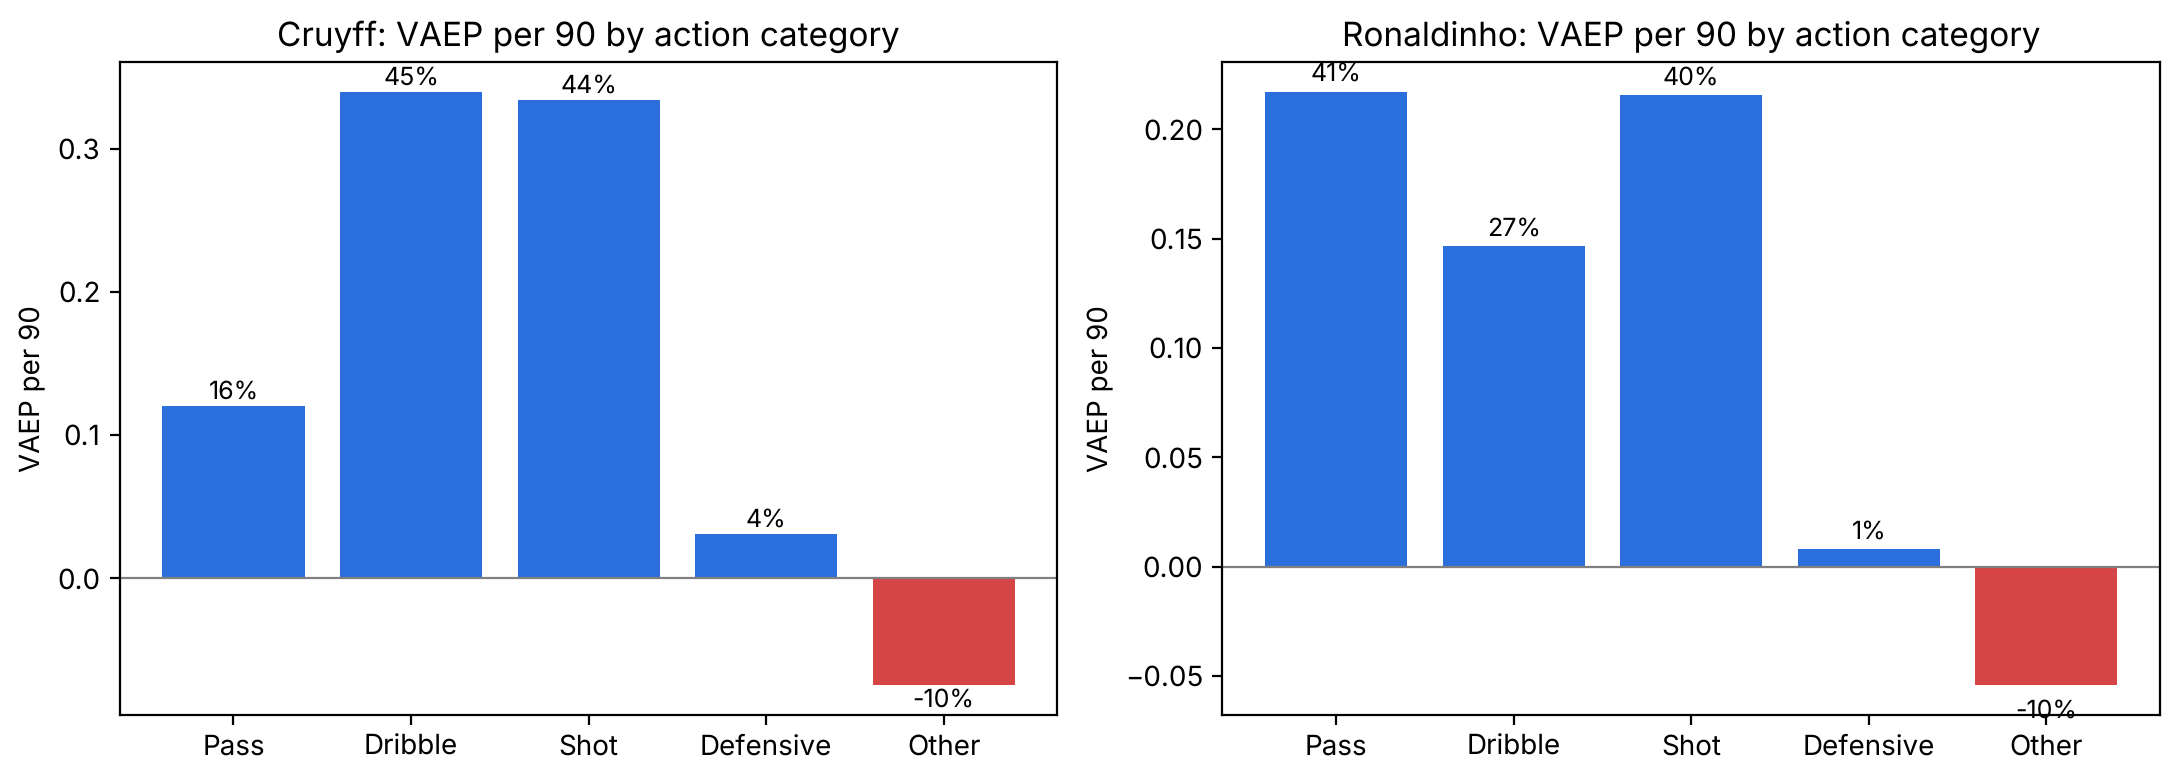

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=False)
for ax, (name, t) in zip(axes, [("Cruyff", cat_legend), ("Ronaldinho", cat_compare)]):
    colors = ["#2a6fdb" if v >= 0 else "#d64545" for v in t.vaep_per90]
    ax.bar(t.index, t.vaep_per90, color=colors)
    for i, (v, s) in enumerate(zip(t.vaep_per90, t["share_of_vaep_%"])):
        ax.text(i, v + (0.005 if v >= 0 else -0.015), f"{s:.0f}%", ha="center", fontsize=9)
    ax.axhline(0, color="grey", lw=0.8)
    ax.set_title(f"{name}: VAEP per 90 by action category")
    ax.set_ylabel("VAEP per 90")
plt.tight_layout()
plt.savefig(f"{OUT}/q1_category.png", dpi=200)
plt.show()

### 1-3. 같은 경기에 뛴 동료·상대 중 배정 선수의 90분당 VAEP 순위
- **경기별 순위**: 각 경기에서 그 경기에 출전한 모든 선수(양 팀) 중 **출전 10분 이상** 선수만 대상으로 90분당 VAEP 순위를 매깁니다.
- (부록) **1974 월드컵 네덜란드 5경기 통합 순위**: 5경기에 뛴 모든 선수의 VAEP·출전 시간을 합산해, **합산 출전 50분 이상** 선수 중 순위.

In [31]:
MIN_GAME = 10

def player_game_ratings(A_, player_games):
    v = A_.groupby(["game_id", "player_id"])[["vaep_value", "offensive_value", "defensive_value"]].sum().reset_index()
    pg = player_games[["game_id", "player_id", "player_name", "nickname", "team_id", "minutes_played"]]
    r = pg.merge(v, how="left", on=["game_id", "player_id"]).fillna({"vaep_value": 0, "offensive_value": 0, "defensive_value": 0})
    r["name"] = r.nickname.fillna(r.player_name)
    r = r[r.minutes_played >= MIN_GAME].copy()
    r["vaep_per90"] = r.vaep_value * 90 / r.minutes_played
    r["rank"] = r.groupby("game_id").vaep_per90.rank(ascending=False, method="min").astype(int)
    r["n_players"] = r.groupby("game_id").player_id.transform("size")
    return r

def rank_table(A_, games, player_games, teams, pid):
    r = player_game_ratings(A_, player_games)
    tn = teams.set_index("team_id").team_name
    rows = []
    for g in games.itertuples():
        rg = r[r.game_id == g.game_id].sort_values("vaep_per90", ascending=False)
        me = rg[rg.player_id == pid].iloc[0]
        mates = rg[(rg.team_id == me.team_id)]
        best = rg.iloc[0]
        rows.append({"date": str(g.game_date)[:10], "match": game_label(g, teams),
                     "vaep_per90": me.vaep_per90, "rank_all": f"{me['rank']}/{me.n_players}",
                     "rank_in_team": f"{int((mates.vaep_per90 > me.vaep_per90).sum()) + 1}/{len(mates)}",
                     "top_player": f"{best['name']} ({tn[best.team_id]})", "top_per90": best.vaep_per90})
    return pd.DataFrame(rows), r

legend_rank, legend_ratings = rank_table(A_legend, legend_games, player_games_legend, teams_legend, LEGEND_ID)
compare_rank, compare_ratings = rank_table(A_compare, compare_games, player_games_compare, teams_compare, COMPARE_ID)
legend_rank.to_csv(f"{OUT}/q1_cruyff_rank.csv", index=False)
compare_rank.to_csv(f"{OUT}/q1_ronaldinho_rank.csv", index=False)
legend_rank.round(3)

,date,match,vaep_per90,rank_all,rank_in_team,top_player,top_per90
0,1971-06-02,Ajax 2-0 Panathinaikos,0.242,10/24,8/13,Arie Haan (Ajax),1.720
1,1972-05-31,Ajax 2-0 Inter Milan,1.463,1/24,1/11,Johan Cruyff (Ajax),1.463
2,1973-05-30,Ajax 1-0 Juventus,0.311,3/24,3/11,Piet Keizer (Ajax),1.212
3,1974-02-17,Real Madrid 0-5 Barcelona,1.289,3/24,3/12,Juan Manuel Asensi (Barcelona),1.958
4,1974-06-19,Netherlands 0-0 Sweden,1.382,1/25,1/12,Johan Cruyff (Netherlands),1.382
5,1974-06-26,Netherlands 4-0 Argentina,2.237,1/24,1/11,Johan Cruyff (Netherlands),2.237
6,1974-06-30,German DR 0-2 Netherlands,-0.002,13/24,7/11,Rob Rensenbrink (Netherlands),0.918
7,1974-07-03,Netherlands 2-0 Brazil,0.644,2/24,2/12,Johan Neeskens (Netherlands),0.761
8,1974-07-07,Netherlands 1-2 Germany,-0.213,22/24,11/13,Gerhard Müller (Germany),0.579
9,1978-04-19,Barcelona 3-1 Las Palmas,0.172,7/25,4/13,Carles Rexach (Barcelona),0.972


In [32]:
compare_rank.round(3)

,date,match,vaep_per90,rank_all,rank_in_team,top_player,top_per90
0,2004-10-16,Espanyol 0-1 Barcelona,0.265,4/27,3/13,Deco (Barcelona),1.110
1,2004-10-24,Barcelona 3-0 Osasuna,0.934,2/28,2/14,Samuel Eto'o (Barcelona),1.099
2,2004-12-04,Barcelona 4-0 Málaga,0.113,7/26,7/12,Samuel Eto'o (Barcelona),1.441
3,2004-12-11,Albacete 1-2 Barcelona,0.003,17/24,8/11,Xavi (Barcelona),1.198
4,2004-12-21,Barcelona 2-1 Levante UD,0.480,3/25,2/12,Deco (Barcelona),1.657
5,2005-04-17,Barcelona 2-0 Getafe,1.382,1/25,1/11,Ronaldinho (Barcelona),1.382
6,2005-05-01,Barcelona 2-0 Albacete,0.224,5/25,4/12,Rafael Márquez (Barcelona),0.507
7,2005-10-01,Barcelona 2-2 Real Zaragoza,0.337,6/27,5/14,Diego Milito (Real Zaragoza),0.695
8,2005-10-22,Barcelona 3-0 Osasuna,0.658,4/28,4/14,Ludovic Giuly (Barcelona),6.138
9,2005-10-26,Barcelona 2-0 Málaga,0.616,3/28,2/14,Henrik Larsson (Barcelona),2.064


In [33]:
def rank_summary(rt, name):
    r = rt.rank_all.str.split("/").str[0].astype(int)
    n = rt.rank_all.str.split("/").str[1].astype(int)
    return {"player": name, "games": len(rt), "median_rank": r.median(), "mean_rank": r.mean(),
            "rank1_games": int((r == 1).sum()), "top3_games": int((r <= 3).sum()),
            "mean_percentile_%": float((100 * (1 - (r - 1) / (n - 1))).mean())}

rank_sum = pd.DataFrame([rank_summary(legend_rank, "Cruyff"), rank_summary(compare_rank, "Ronaldinho")])
rank_sum.to_csv(f"{OUT}/q1_rank_summary.csv", index=False)
rank_sum.round(2)

,player,games,median_rank,mean_rank,rank1_games,top3_games,mean_percentile_%
0,Cruyff,10,3.0,6.30,3,6,77.07
1,Ronaldinho,59,5.0,9.73,8,21,66.09


In [34]:
# (부록) 1974 월드컵 네덜란드 5경기 통합 순위 — 합산 출전 50분 이상
MIN_WC = 50
wc_ids = legend_games[(legend_games.competition_id == 43) & (legend_games.season_id == 51)].game_id
A_wc = A_legend[A_legend.game_id.isin(wc_ids)]
pg_wc = player_games_legend[player_games_legend.game_id.isin(wc_ids)]
v = A_wc.groupby("player_id")[["vaep_value", "offensive_value", "defensive_value"]].sum()
m = pg_wc.groupby("player_id").agg(minutes=("minutes_played", "sum"), games=("game_id", "nunique"))
info = players_legend.set_index("player_id")
wc = m.join(v).fillna(0)
wc["name"] = info.nickname.fillna(info.player_name).reindex(wc.index)
# 팀은 월드컵 경기의 소속(대표팀)으로 — players_legend 는 첫 등장 경기(클럽) 기준이므로 쓰지 않음
wc["team"] = pg_wc.drop_duplicates("player_id").set_index("player_id").team_id.map(teams_legend.set_index("team_id").team_name).reindex(wc.index)
wc = wc[wc.minutes >= MIN_WC]
wc["vaep_per90"] = wc.vaep_value * 90 / wc.minutes
wc = wc.sort_values("vaep_per90", ascending=False).reset_index()
wc.index = wc.index + 1
wc.to_csv(f"{OUT}/q1_wc1974_combined_rank.csv")
print("Cruyff combined rank:", wc[wc.player_id == LEGEND_ID].index[0], "/", len(wc))
wc[["name", "team", "games", "minutes", "vaep_value", "vaep_per90"]].head(10).round(3)

Cruyff combined rank: 1 / 67


,name,team,games,minutes,vaep_value,vaep_per90
1,Johan Cruyff,Netherlands,5,449,4.074,0.817
2,Gerhard Müller,Germany,1,90,0.579,0.579
3,Paul Breitner,Germany,1,90,0.443,0.443
4,Ruud Krol,Netherlands,5,449,2.119,0.425
5,Willem van Hanegem,Netherlands,5,431,1.862,0.389
6,Roberto Perfumo,Argentina,1,92,0.386,0.378
7,Johan Neeskens,Netherlands,5,443,1.676,0.340
8,Luís Pereira,Brazil,1,83,0.262,0.284
9,Paulo César Carpegiani,Brazil,1,91,0.274,0.271
10,Ronnie Carl Hellström,Sweden,1,88,0.243,0.249


---
## 문제 2. 검증 — 두 데이터는 무엇이 다른가
- **경기 단위(match level)**: 두 데이터셋에 포함된 경기의 *모든* 행동(양 팀) — 모델이 실제로 보게 되는 데이터 분포의 차이.
- **선수 단위(player level)**: 크루이프/호나우지뉴 본인의 행동만.
- 드리블 돌파 비율 = take_on 비율(성공률 병기). 공 운반(dribble)은 별도 열로 둡니다.

In [35]:
def distribution(a, n_games, minutes=None):
    n = len(a)
    to = a[a.type_name == "take_on"]
    d = {"actions_per_game": n / n_games,
         "pass_%": 100 * (a.category == "Pass").mean(),
         "carry(dribble)_%": 100 * (a.type_name == "dribble").mean(),
         "take_on_%": 100 * (a.type_name == "take_on").mean(),
         "take_on_success_%": 100 * (to.result_name == "success").mean() if len(to) else np.nan,
         "shot_%": 100 * (a.category == "Shot").mean(),
         "defensive_%": 100 * (a.category == "Defensive").mean(),
         "pass_success_%": 100 * (a[a.category == "Pass"].result_name == "success").mean()}
    if minutes is not None:
        d["actions_per90"] = n * 90 / minutes
    return d

dist = pd.DataFrame({
    "Cruyff games (all actions)": distribution(A_legend, len(legend_games)),
    "Ronaldinho games (all actions)": distribution(A_compare, len(compare_games)),
    "Cruyff (own actions)": distribution(A_legend[A_legend.player_id == LEGEND_ID], len(legend_games), legend_pg.minutes.sum()),
    "Ronaldinho (own actions)": distribution(A_compare[A_compare.player_id == COMPARE_ID], len(compare_games), compare_pg.minutes.sum()),
}).T
dist.to_csv(f"{OUT}/q2_distribution.csv")
dist.round(2)

,actions_per_game,pass_%,carry(dribble)_%,take_on_%,take_on_success_%,shot_%,defensive_%,pass_success_%,actions_per90
Cruyff games (all actions),1846.50,45.22,39.42,2.71,62.87,1.64,7.06,75.90,NaN
Ronaldinho games (all actions),2047.90,45.71,41.17,2.29,63.95,1.24,6.27,80.02,NaN
Cruyff (own actions),109.40,40.13,44.52,6.58,73.61,2.65,2.01,68.56,110.38
Ronaldinho (own actions),115.36,41.51,46.72,4.86,66.47,3.23,0.59,75.89,122.51


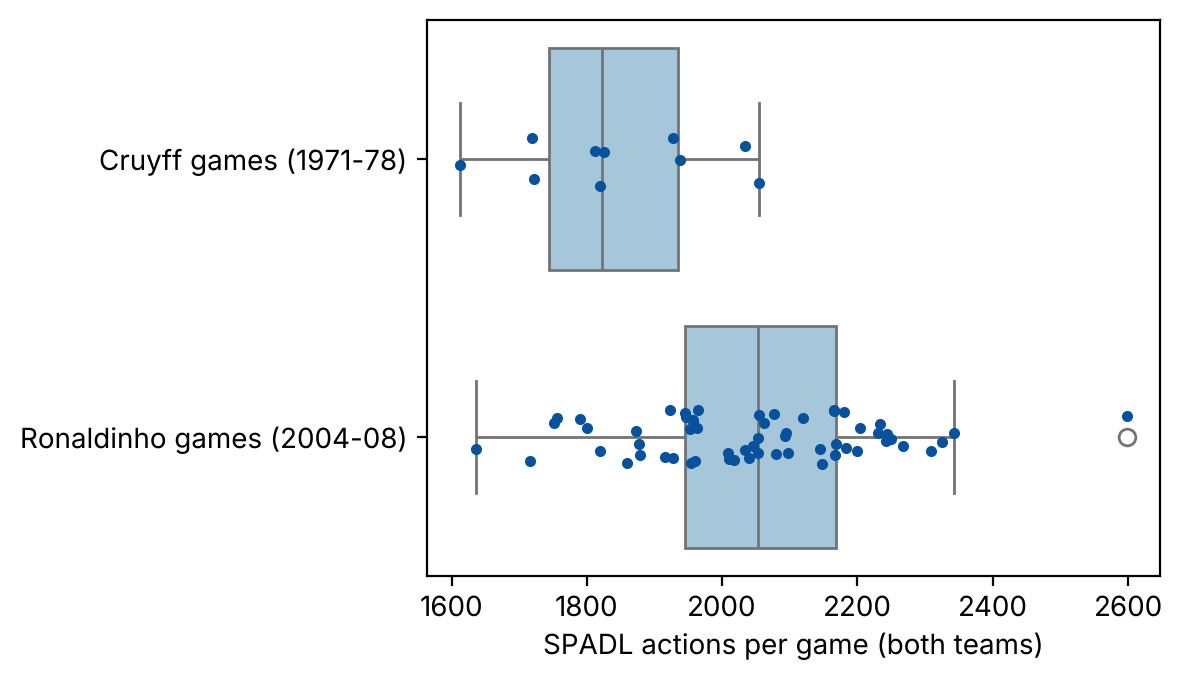

In [36]:
# 경기별 행동 수 분포
fig, ax = plt.subplots(figsize=(6, 3.5))
apg = pd.concat([
    A_legend.groupby("game_id").size().rename("n").to_frame().assign(dataset="Cruyff games (1971-78)"),
    A_compare.groupby("game_id").size().rename("n").to_frame().assign(dataset="Ronaldinho games (2004-08)"),
])
sns.boxplot(data=apg, x="n", y="dataset", ax=ax, color="#9ecae1")
sns.stripplot(data=apg, x="n", y="dataset", ax=ax, color="#08519c", size=4)
ax.set_xlabel("SPADL actions per game (both teams)"); ax.set_ylabel("")
plt.tight_layout(); plt.savefig(f"{OUT}/q2_actions_per_game.png", dpi=200); plt.show()

### 2-2. 행동 10개 안에 득점/실점이 나온 비율 (`lab.scores`, `lab.concedes`, 기본 nr_actions=10)

In [37]:
lab_rates = pd.DataFrame({
    "Cruyff games": {"P(scores)_%": 100 * Y_legend.scores.mean(), "P(concedes)_%": 100 * Y_legend.concedes.mean(),
                      "n_actions": len(Y_legend), "goals_per_game": (A_legend.type_name.str.contains("shot") & (A_legend.result_name == "success")).sum() / len(legend_games)},
    "Ronaldinho games": {"P(scores)_%": 100 * Y_compare.scores.mean(), "P(concedes)_%": 100 * Y_compare.concedes.mean(),
                          "n_actions": len(Y_compare), "goals_per_game": (A_compare.type_name.str.contains("shot") & (A_compare.result_name == "success")).sum() / len(compare_games)},
    "Model train (meta)": {"P(scores)_%": 100 * meta["metrics"]["scores"]["train_base_rate"], "P(concedes)_%": 100 * meta["metrics"]["concedes"]["train_base_rate"]},
    "WC2018 test (meta)": {"P(scores)_%": 100 * meta["metrics"]["scores"]["test_base_rate"], "P(concedes)_%": 100 * meta["metrics"]["concedes"]["test_base_rate"]},
}).T
lab_rates.to_csv(f"{OUT}/q2_label_rates.csv")
lab_rates.round(3)

,P(scores)_%,P(concedes)_%,n_actions,goals_per_game
Cruyff games,1.137,0.217,18465.0,2.500
Ronaldinho games,1.184,0.214,120826.0,2.864
Model train (meta),1.184,0.191,NaN,NaN
WC2018 test (meta),1.048,0.272,NaN,NaN


### 2-3. 제공 모델의 AUC와 Brier score
위 `evaluate` 셀 출력을 표로 정리하고, WC2018 테스트(제공 모델 meta) 값과 나란히 둡니다.
크루이프 데이터는 10경기뿐이어서 양성(득점 라벨) 수가 적으므로, **경기 단위 부트스트랩(1,000회) 95% 구간**도 함께 계산합니다.
Brier score는 기저율에 크게 좌우되므로, 항상 기저율을 예측하는 모델 대비 개선율인 **Brier skill score (BSS = 1 − Brier / Brier_ref)**도 함께 봅니다.

In [38]:
met = pd.DataFrame(metric_rows)
met["brier_ref"] = met.base_rate * (1 - met.base_rate)
met["BSS"] = 1 - met.brier_score / met.brier_ref
ref = pd.DataFrame([{"dataset": "WC2018 test (meta)", "label": k, "auc": v["test_auc"], "brier_score": v["test_brier"],
                     "log_loss": v["test_logloss"], "base_rate": v["test_base_rate"]} for k, v in meta["metrics"].items()])
ref["brier_ref"] = ref.base_rate * (1 - ref.base_rate)
ref["BSS"] = 1 - ref.brier_score / ref.brier_ref

rng = np.random.default_rng(42)
def boot_ci(A_, label, B=1000):
    gids = A_.game_id.unique()
    grp = {g: d for g, d in A_.groupby("game_id")}
    aucs, briers = [], []
    for _ in range(B):
        d = pd.concat([grp[g] for g in rng.choice(gids, len(gids), replace=True)])
        y, p = d[f"y_{label}"], d[label]
        if y.nunique() < 2:
            continue
        aucs.append(roc_auc_score(y, p)); briers.append(brier_score_loss(y, p))
    return np.percentile(aucs, [2.5, 97.5]), np.percentile(briers, [2.5, 97.5])

ci = []
for name, A_ in [("Cruyff", A_legend), ("Ronaldinho", A_compare)]:
    for label in ["scores", "concedes"]:
        (a_lo, a_hi), (b_lo, b_hi) = boot_ci(A_, label)
        ci.append({"dataset": name, "label": label, "auc_95ci": f"[{a_lo:.3f}, {a_hi:.3f}]", "brier_95ci": f"[{b_lo:.4f}, {b_hi:.4f}]"})
met = met.merge(pd.DataFrame(ci), on=["dataset", "label"])
metrics_table = pd.concat([met, ref], ignore_index=True)[
    ["dataset", "label", "n_pos", "base_rate", "mean_pred", "auc", "auc_95ci", "brier_score", "brier_95ci", "BSS", "log_loss", "ece"]]
metrics_table.to_csv(f"{OUT}/q2_metrics.csv", index=False)
metrics_table.round(4)

,dataset,label,n_pos,base_rate,mean_pred,auc,auc_95ci,brier_score,brier_95ci,BSS,log_loss,ece
0,Cruyff,scores,210.0,0.0114,0.0122,0.7635,"[0.712, 0.807]",0.0098,"[0.0069, 0.0127]",0.1305,0.0529,0.0009
1,Cruyff,concedes,40.0,0.0022,0.0030,0.7010,"[0.505, 0.846]",0.0023,"[0.0010, 0.0038]",-0.0452,0.0152,0.0009
2,Ronaldinho,scores,1431.0,0.0118,0.0112,0.7815,"[0.761, 0.803]",0.0101,"[0.0089, 0.0113]",0.1328,0.0530,0.0011
3,Ronaldinho,concedes,259.0,0.0021,0.0021,0.7863,"[0.730, 0.833]",0.0021,"[0.0017, 0.0026]",0.0155,0.0136,0.0004
4,WC2018 test (meta),scores,NaN,0.0105,NaN,0.8122,NaN,0.0089,NaN,0.1443,0.0463,NaN
5,WC2018 test (meta),concedes,NaN,0.0027,NaN,0.7133,NaN,0.0027,NaN,0.0135,0.0180,NaN


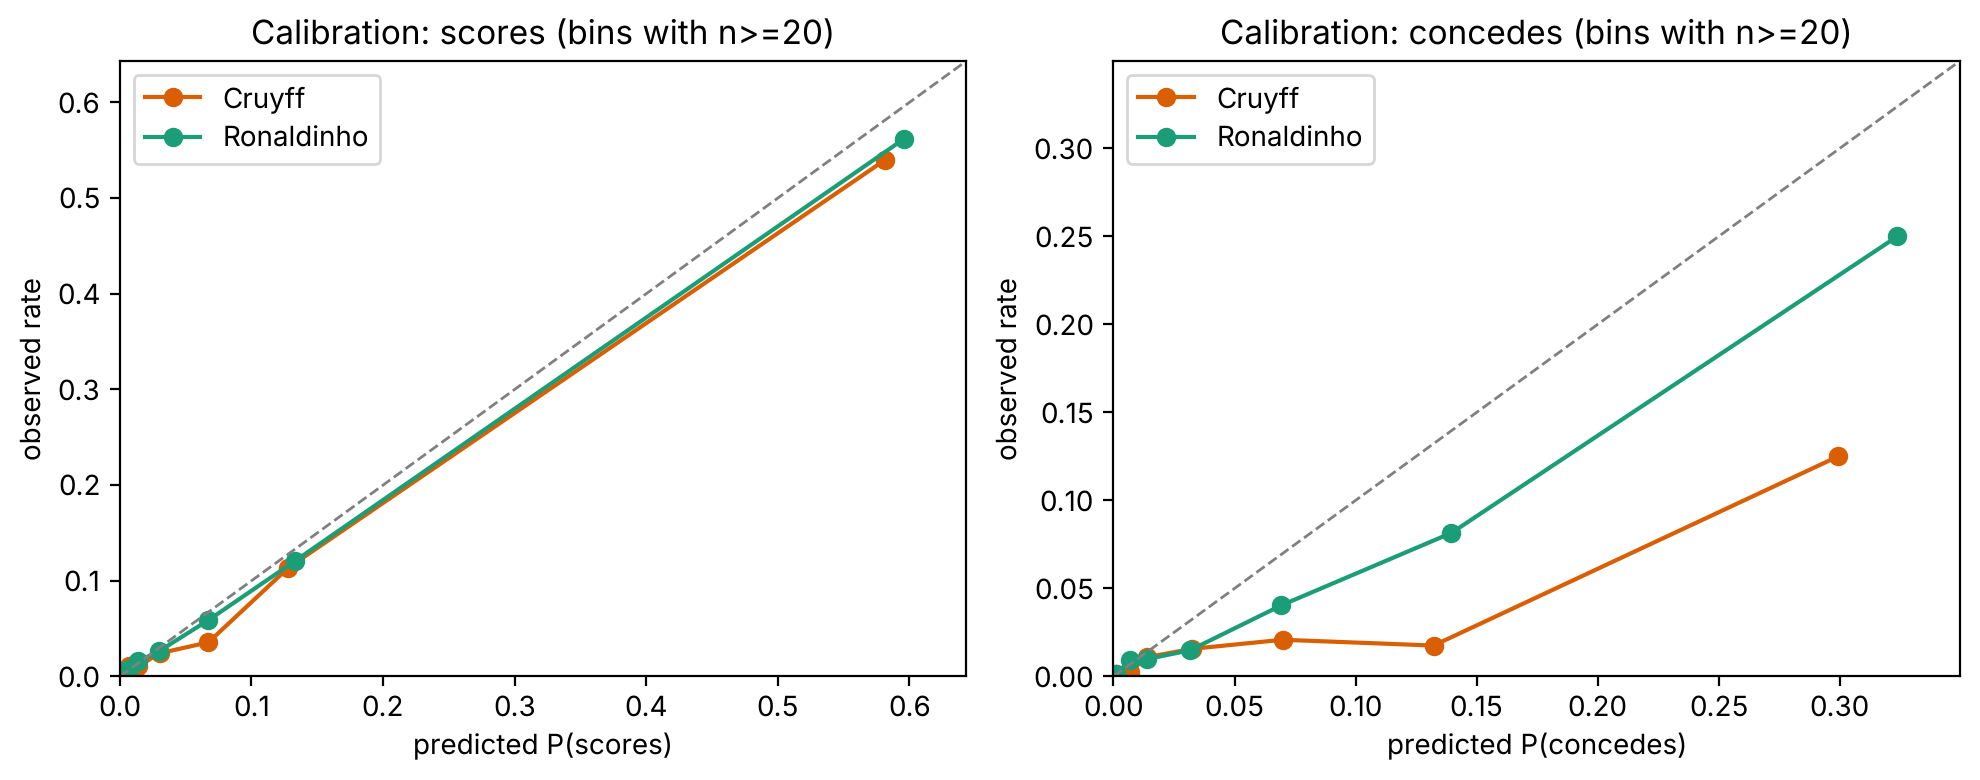

In [39]:
# 신뢰도 곡선(calibration) — 득점 모델. 예측 확률 구간별 실제 득점 비율.
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
bins = [0, 0.005, 0.01, 0.02, 0.05, 0.1, 0.2, 1.0]
for ax, label in zip(axes, ["scores", "concedes"]):
    for name, A_, c in [("Cruyff", A_legend, "#d95f02"), ("Ronaldinho", A_compare, "#1b9e77")]:
        d = A_.assign(bin=pd.cut(A_[label], bins, include_lowest=True)).groupby("bin", observed=True).agg(
            pred=(label, "mean"), obs=(f"y_{label}", "mean"), n=(label, "size"))
        d = d[d.n >= 20]
        ax.plot(d.pred, d.obs, "o-", color=c, label=name)
    lim = max(l.get_xdata().max() for l in ax.get_lines()) * 1.08
    lim = max(lim, max(l.get_ydata().max() for l in ax.get_lines()) * 1.08)
    ax.plot([0, lim], [0, lim], "--", color="grey", lw=1)
    ax.set_xlim(0, lim); ax.set_ylim(0, lim)
    ax.set_xlabel(f"predicted P({label})"); ax.set_ylabel("observed rate"); ax.set_title(f"Calibration: {label} (bins with n>=20)")
    ax.legend()
plt.tight_layout(); plt.savefig(f"{OUT}/q2_calibration.png", dpi=200); plt.show()

### 2-4. 주장 분류 (직접 검증 가능 / 간접 검증 가능 / 현재 데이터로는 불가)
분류와 이유는 보고서에 서술했으며, 근거가 되는 숫자는 위 표(2-1~2-3)의 출력입니다.

| 주장 | 분류 |
|---|---|
| ① 이 모델의 득점 확률 예측은 배정 선수의 경기에서도 잘 맞는다. | 직접 검증 가능 |
| ② 90분당 VAEP가 비교 대상보다 높으므로 배정 선수가 더 좋은 선수다. | 현재 데이터로는 불가 |
| ③ 이 패스의 VAEP +0.03은 그 패스가 실제로 만든 가치와 같다. | 현재 데이터로는 불가 (평균적 보정만 간접 확인) |

---
## 문제 3. 시각화 — 대표 장면
Week 9의 `nice_time` / `plot_actions` 셀을 그대로 사용합니다.

In [40]:
# [Week 9 cell] — plot_actions 가 참조하는 전역 df_teams / df_players 를 크루이프 데이터로 지정
df_teams, df_players = teams_legend, players_legend

def nice_time(row):
	minute = int((row.period_id-1)*45 +row.time_seconds // 60)
	second = int(row.time_seconds % 60)
	return f"{minute}m{second}s"

def plot_actions(a: pd.DataFrame, g: pd.Series) -> None:
	home_team_name = df_teams[df_teams.team_id == g.home_team_id].team_name.values[0]
	away_team_name = df_teams[df_teams.team_id == g.away_team_id].team_name.values[0]

	minute = int((a.period_id.values[0]-1) * 45 + a.time_seconds.values[0] // 60)
	game_info = f"{g.game_date} {home_team_name} {g.home_score}-{g.away_score} {away_team_name} {minute + 1}'"
	print(game_info)

	a["player_name"] = a.player_id.map(df_players.set_index("player_id").player_name)
	a["team_name"] = a.team_id.map(df_teams.set_index("team_id").team_name)
	a["type_name"] = a.type_id.map(spadl.config.actiontypes_df().type_name.to_dict())
	a["result_name"] = a.result_id.map(spadl.config.results_df().result_name.to_dict())
	a["nice_time"] = a.apply(nice_time, axis=1)

	if "vaep_value" in a.columns:
		for col in ["scores", "concedes", "offensive_value", "defensive_value", "vaep_value"]:
			a[col] = a[col].map(lambda x: f"{x:.3f}")

		labels = a[["nice_time", "type_name", "result_name", "player_name", "team_name", "scores", "concedes", "vaep_value"]]
		labeltitle = ["time", "actiontype", "result", "player", "team", "scores", "concedes", "vaep_value"]
	else:
		labels = a[["nice_time", "type_name", "player_name", "team_name"]]
		labeltitle = ["time", "actiontype", "player", "team"]

	mps.actions(
		location=a[["start_x", "start_y", "end_x", "end_y"]],
		action_type=a.type_name,
		team= a.team_name,
		result= a.result_name == "success",
		label=labels,
		labeltitle=labeltitle,
		zoom=False,
		figsize=6,
		color="green"
	)

In [41]:
# 후보 탐색: Week 9 셀처럼 크루이프 행동을 VAEP 순으로 정렬
sorted_A = A_legend.sort_values("vaep_value", ascending=False)
sorted_A = sorted_A[sorted_A.player_id == LEGEND_ID]
cand = sorted_A.head(10).copy()
cand["time"] = cand.apply(nice_time, axis=1)
cand["match"] = cand.game_id.map({g.game_id: game_label(g, teams_legend) for g in legend_games.itertuples()})
cand[["match", "time", "type_name", "result_name", "scores", "concedes", "vaep_value"]].round(3)

,match,time,type_name,result_name,scores,concedes,vaep_value
11150,Netherlands 4-0 Argentina,91m14s,shot,success,1.000,0.000,0.915
6386,Real Madrid 0-5 Barcelona,34m57s,shot,success,1.000,0.001,0.869
9353,Netherlands 4-0 Argentina,10m47s,shot,success,1.000,0.001,0.690
949,Ajax 2-0 Inter Milan,46m46s,shot,success,1.000,0.000,0.638
14493,Netherlands 2-0 Brazil,64m26s,shot,success,1.000,0.000,0.615
1563,Ajax 2-0 Inter Milan,76m11s,shot,success,0.591,0.002,0.527
724,Ajax 2-0 Inter Milan,34m8s,cross,success,0.401,0.000,0.393
7911,Netherlands 0-0 Sweden,28m34s,cross,success,0.430,0.001,0.379
6989,Real Madrid 0-5 Barcelona,68m13s,freekick_crossed,success,0.277,0.000,0.277
15827,Netherlands 1-2 Germany,36m26s,pass,success,0.291,0.001,0.236


,time,player_name,type_name,result_name,bodypart_name,scores,concedes,offensive_value,defensive_value,vaep_value
1,63m52s,Jair Ventura Filho,foul,fail,foot,0.002,0.001,-0.005,-0.000,-0.005
2,64m8s,Arie Haan,freekick_short,success,foot_right,0.001,0.001,0.001,-0.001,0.001
3,64m8s,Willem van Hanegem,pass,success,foot_left,0.001,0.001,0.000,-0.001,-0.001
4,64m10s,Wim Rijsbergen,dribble,success,foot,0.007,0.001,0.005,0.001,0.006
5,64m15s,Wim Rijsbergen,pass,success,foot_right,0.004,0.000,-0.003,0.001,-0.002
6,64m17s,Ruud Krol,dribble,success,foot,0.005,0.000,0.001,-0.000,0.001
7,64m18s,Ruud Krol,pass,success,foot_right,0.014,0.000,0.009,-0.000,0.009
8,64m19s,Rob Rensenbrink,dribble,success,foot,0.010,0.000,-0.004,-0.000,-0.004
9,64m21s,Rob Rensenbrink,pass,success,foot_right,0.029,0.000,0.019,0.000,0.019
10,64m24s,Ruud Krol,dribble,success,foot,0.024,0.000,-0.005,-0.000,-0.005


1974-07-03 18:30:00 Netherlands 2-0 Brazil 64'


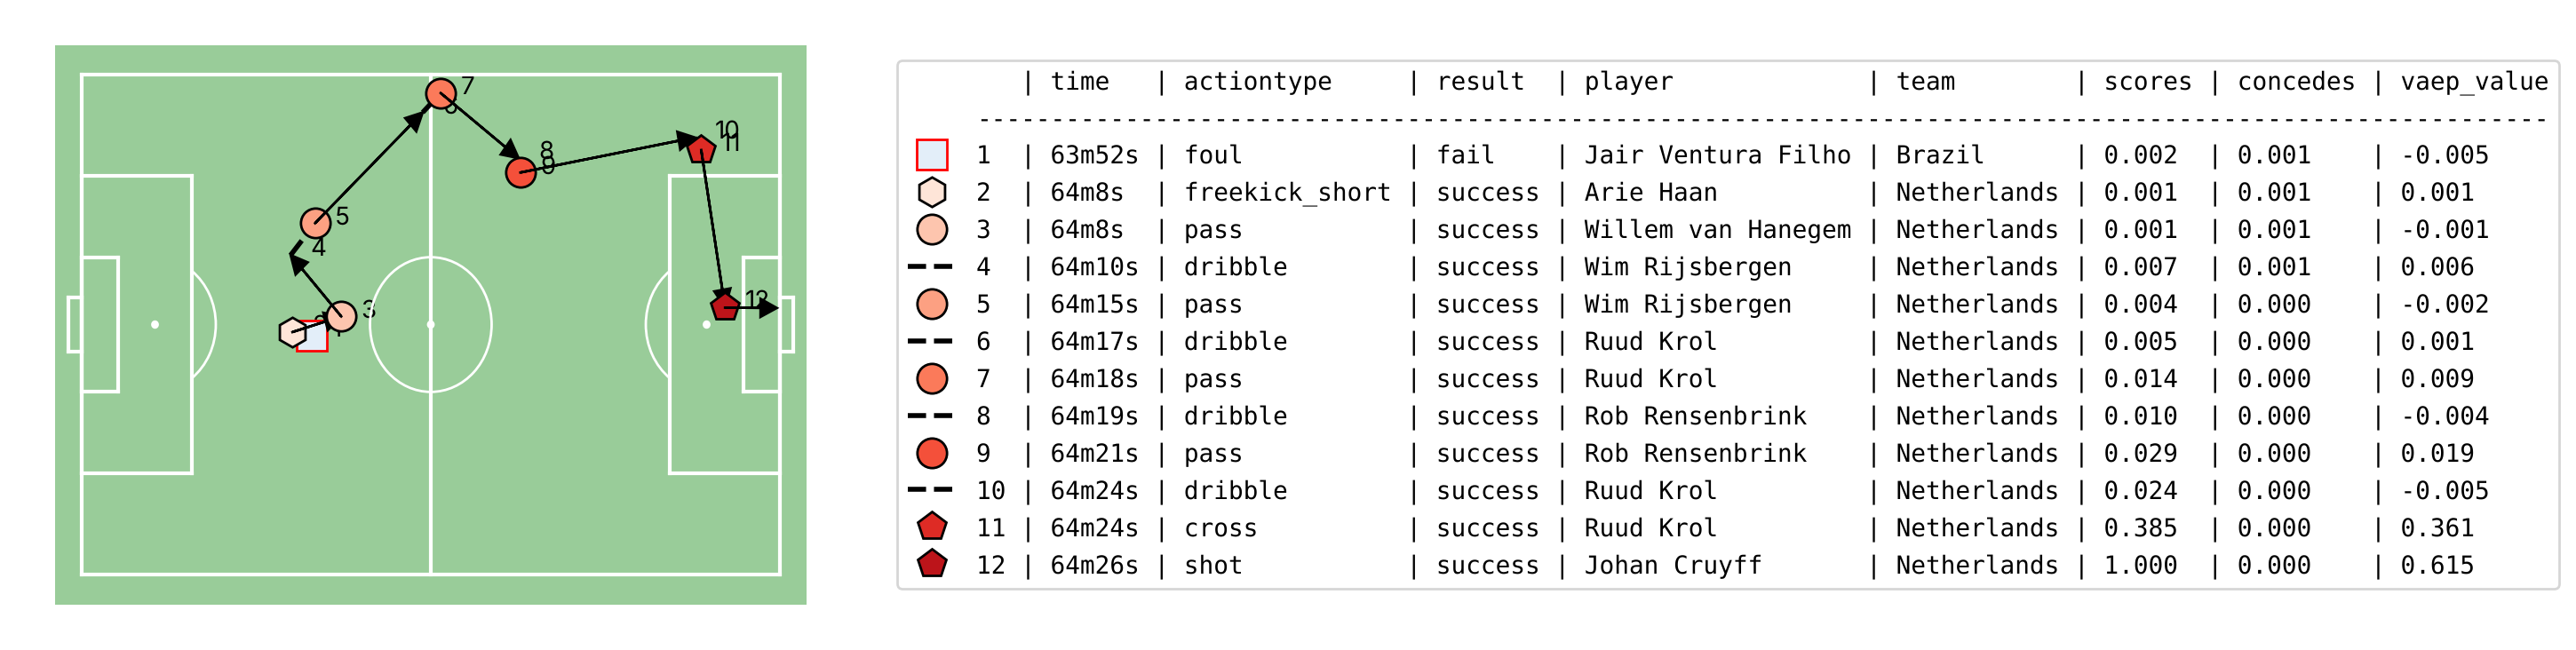

In [42]:
# 대표 장면: 1974 월드컵 2차 조별리그 네덜란드 2-0 브라질, 후반 크루이프 발리골 (Krol 크로스 → Cruyff 발리)
# 위 후보 표의 'Netherlands 2-0 Brazil 64m26s shot' 행
BRA_GAME = 3888719
row = list(sorted_A[(sorted_A.game_id == BRA_GAME) & (sorted_A.type_name == "shot") & (sorted_A.result_name == "success")][0:1].itertuples())[0]

# [Week 9 cell] 과 같은 방식으로 행동 구간을 잘라 plot_actions 에 넘김 (Week 9: A[i-3 : i+1] → 여기서는 골 직전 행동 12개)
i = row.Index
a = A_legend[i - 11 : i+1].copy()
g = list(legend_games[legend_games.game_id == a.game_id.values[0]].itertuples())[0]

scene = a[["period_id", "time_seconds", "player_name", "type_name", "result_name", "bodypart_name",
           "scores", "concedes", "offensive_value", "defensive_value", "vaep_value"]].copy()
scene.insert(0, "time", a.apply(nice_time, axis=1))
scene = scene.drop(columns=["period_id", "time_seconds"]).reset_index(drop=True)
scene.index = scene.index + 1
scene.to_csv(f"{OUT}/q3_scene.csv")
display(scene.round(3))

_show = plt.show
plt.show = lambda *args, **kw: (plt.savefig(f"{OUT}/q3_scene.png", dpi=200, bbox_inches="tight"), _show())
plot_actions(a, g)
plt.show = _show

---
## 문제 4. 결론
보고서 '문제 4. 결론' 참조.